
## Trzy grupy uczenia maszynowego

Zanim przejdziemy do regresji — przypomnij sobie lub zapamiętaj, że uczenie maszynowe dzieli się na **trzy główne grupy**:

| Grupa | Co to jest? | Przykłady |
|---|---|---|
| **Uczenie z nadzorem** *(supervised)* | Mamy dane + poprawne odpowiedzi, model się uczy dopasowywać | Regresja, klasyfikacja |
| **Uczenie bez nadzoru** *(unsupervised)* | Mamy tylko dane bez odpowiedzi, model szuka wzorców | Klasteryzacja, PCA |
| **Uczenie ze wzmocnieniem** *(reinforcement)* | Agent uczy się przez próby i błędy, dostaje nagrody | Gry komputerowe, robotyka |

Regresja liniowa należy do **uczenia z nadzorem** — trenujemy ją na parach $(x, y)$ gdzie $y$ to znana cena mieszkania.

# Regresja liniowa — wersja rozszerzona

> **Ta wersja notebooka zawiera dodatkowe wyjaśnienia**, które pomogą Ci zrozumieć materiał samodzielnie, w domu, bez prowadzącego. Wszystkie zadania, podpowiedzi i rozwiązania są identyczne jak w wersji podstawowej — tu po prostu więcej tłumaczymy *dlaczego*.

## Co to jest regresja?

**Regresja** to rodzaj uczenia maszynowego, w którym próbujemy przewidzieć **liczbę** (wartość ciągłą) na podstawie innych danych. Przykłady:

| Co chcemy przewidzieć? | Na podstawie czego? |
|---|---|
| Cena mieszkania | Powierzchnia, liczba pokoi, lokalizacja |
| Temperatura jutro | Temperatura dziś, ciśnienie, wilgotność |
| Czas dojazdu do pracy | Pora dnia, pogoda, dzień tygodnia |
| Sprzedaż w sklepie | Promocje, sezon, dzień tygodnia |

Regresja różni się od **klasyfikacji** (którą zobaczysz w kolejnym notebooku) tym, że w klasyfikacji przewidujemy **kategorię** (np. spam / nie-spam), a w regresji — **liczbę**.

## Co to jest regresja *liniowa*?

Najprostszy model regresji: zakładamy, że związek między zmiennymi jest **linią prostą** (w 2D), **płaszczyzną** (w 3D), albo **hiperpłaszczyzną** (w wyższych wymiarach).

Mimo swojej prostoty, regresja liniowa:
- jest **podstawą** większości bardziej zaawansowanych modeli (sieci neuronowe to w gruncie rzeczy wiele regresji liniowych z nieliniowościami między nimi),
- ma **analityczne rozwiązanie** — nie trzeba jej "trenować" iteracyjnie, można policzyć odpowiedź wzorem,
- jest **interpretowalna** — widzisz wprost, jaka zmienna jak wpływa na wynik.

## Mapa notebooka

1. **Dane** — pobieramy i oglądamy zbiór cen mieszkań.
2. **Wizualizacje** — patrzymy na dane *zanim* zaczniemy modelować (to się nazywa EDA — Exploratory Data Analysis).
3. **Regresja 2D** — jedna zmienna objaśniająca (powierzchnia → cena). Wyprowadzamy wzór z rachunku różniczkowego.
4. **Regresja 3D** — dwie zmienne objaśniające (powierzchnia + sypialnie). Przechodzimy na zapis macierzowy.
5. **Regresja wielomianowa i overfitting** — co się dzieje, gdy model jest *za bardzo* dopasowany do danych.

## Jak pracować z tym notebookiem?

- **Zadania** są oznaczone pytaniem i pustą komórką z komentarzem `# Tutaj wpisz swój kod`.
- **Podpowiedź** — kliknij, aby rozwinąć. Spróbuj sam najpierw, zanim tu zajrzysz.
- **Rozwiązanie** — kliknij, aby rozwinąć. Użyj dopiero po próbie samodzielnej.
- Jeśli coś nie działa — **czytaj komunikaty błędów**. To najważniejsza umiejętność programisty.

---


In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 1 — Intro — czym jest uczenie maszynowe?</b>"))
display(Audio("https://drive.google.com/uc?id=1cayDLA5EIxYUdNb0jERuC-0JcePLK-zN"))

### Uczenie z nadzorem — jak to działa?

Posiadamy zestaw danych treningowych:

$$D = \{(x_1, y_1),\; (x_2, y_2),\; \ldots,\; (x_n, y_n)\}$$

Dążymy do wyznaczenia funkcji $f$, takiej że:

$$f(x) = y$$

Za pomocą tej funkcji możemy dla **nowego** $x$ (nieznanego wcześniej mieszkania) **wypredykować** $y$ (jego cenę).

Na poniższym wykresie widać dwa podejścia — niebieska linia to regresja liniowa, różowa to model wielomianowy. Oba wyznaczone na tych samych danych (czerwone krzyżyki).

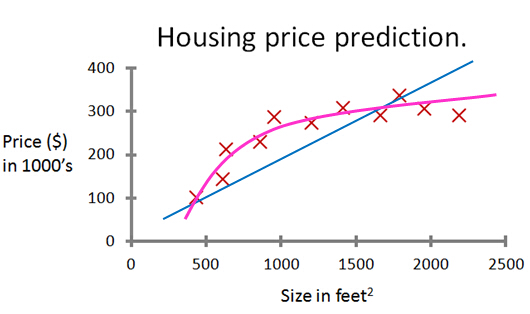

> Ten wykres wróci do nas pod koniec notebooka przy omawianiu overfittingu. Zastanów się już teraz: który model jest lepszy? Bardziej elastyczny (różowy) czy prostszy (niebieski)?


## Ściągnięcie danych oraz ich przegląd

In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 2 — Dane — skąd i jakie?</b>"))
display(Audio("https://drive.google.com/uc?id=1sjGbcHappFpIFewGiqDuhisb4RVEZsud"))

**Proszę odkomentować i wykonać poniższą komórkę jeśli używają państwo Colaba lub MyBinder!**

In [152]:
# import os
# if not os.path.exists('utils.py'):
#     !curl -O https://raw.githubusercontent.com/NXTRSS/MachineLearningCourse/main/utils.py
# from utils import check_and_download_data

# check_and_download_data(files_to_check=["data_houses"])

##### Ściągnięcie wszystkich niezbędbych bibliotek

In [153]:
# === Konfiguracja środowiska ===
# Pakiety są już zainstalowane (Docker/uv).
# Na Colabie — odkomentuj poniższe linie jeśli coś brakuje:
# !pip install -q pandas scikit-learn matplotlib


In [154]:
!python --version

Python 3.9.20


In [155]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
import matplotlib.patches as mpatches
import plotly.express as px
import plotly.graph_objects as go
import os
from scipy import stats


from utils import bcolors


##### Sciągnięcie danych

In [156]:
import os

if os.path.exists("data_houses.csv"):
    df = pd.read_table("data_houses.csv", sep=",")
else:
    print("Plik lokalny nie znaleziony — pobieram z GitHub...")
    url = "https://raw.githubusercontent.com/NXTRSS/MachineLearningCourse/main/data_houses.csv"
    df = pd.read_table(url, sep=",")
    print("OK")

Plik lokalny nie znaleziony — pobieram z GitHub...
OK


##### Wypisać rozmiar danych (liczbę wierszy i liczbę kolumn)

In [157]:
# Tutaj wpisz swój kod


###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

In [207]:
df.shape

(21612, 21)

###### <span style="font-family:Monospace">(21612, 21)</span>

##### Wypisać 10 pierwszych lini danych

In [159]:
# Tutaj wpisz swój kod


###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

In [160]:
#rozwiązanie
df.head(10)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
5,7237550310,20140512T000000,1225000,4,4.50,5420,101930,1.0,0,0,...,11,3890,1530,2001,0,98053,47.6561,-122.005,4760,101930
6,1321400060,20140627T000000,257500,3,2.25,1715,6819,2.0,0,0,...,7,1715,0,1995,0,98003,47.3097,-122.327,2238,6819
7,2008000270,20150115T000000,291850,3,1.50,1060,9711,1.0,0,0,...,7,1060,0,1963,0,98198,47.4095,-122.315,1650,9711
8,2414600126,20150415T000000,229500,3,1.00,1780,7470,1.0,0,0,...,7,1050,730,1960,0,98146,47.5123,-122.337,1780,8113
9,3793500160,20150312T000000,323000,3,2.50,1890,6560,2.0,0,0,...,7,1890,0,2003,0,98038,47.3684,-122.031,2390,7570


###### <div>
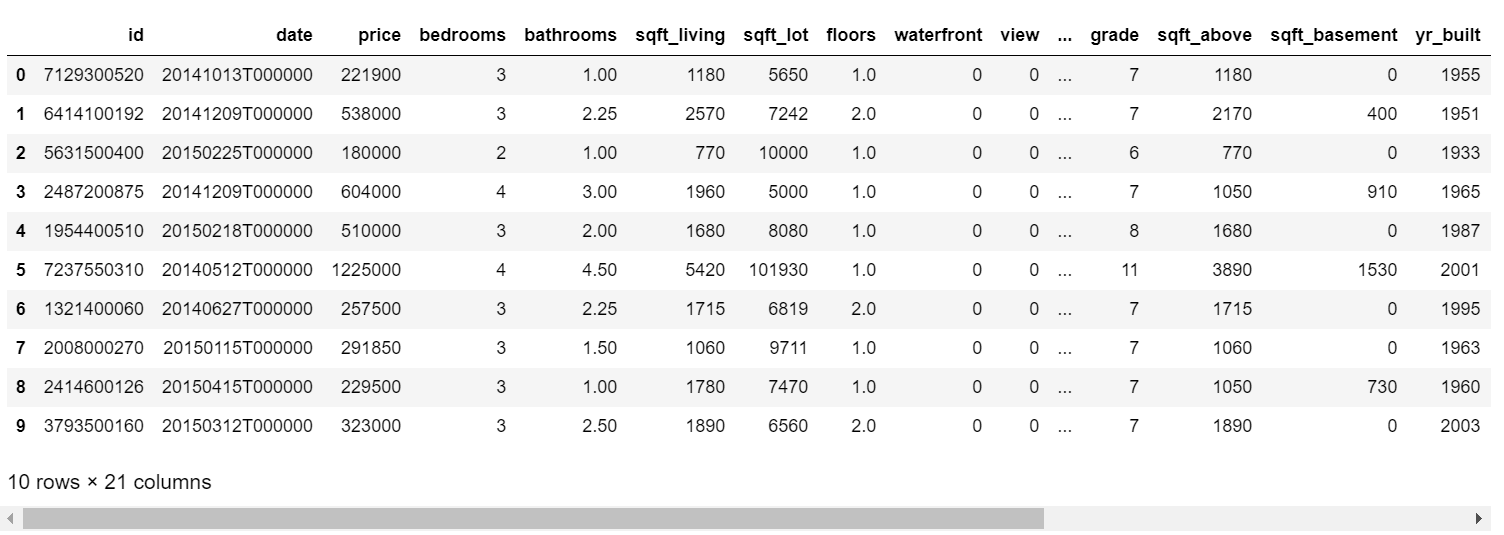
</div>

In [161]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  int64  
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

Ściągnięte dane są dosyć "czyste", ale — jak zobaczymy za chwilę przy wykresie słupkowym liczby sypialni — kryją przynajmniej jeden oczywisty błąd wart usunięcia.

Naszym celem będzie predykowanie jednej zmiennej (zmienna objaśniana) y — **price** czyli cena mieszkania. Do naszego zadania będziemy używać dwóch zmiennych objaśniających: x — **bedrooms** oraz **sqft_living**.

##### Wypisać średnią i medianę zmiennej price

In [162]:
# Tutaj wpisz swój kod


###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

In [163]:
#rozwiązanie
print('Mean',round(df['price'].mean(),2))
print('Median',df['price'].median())

Mean 540088.14
Median 450000.0


###### 
<span style="font-family:Monospace"> Mean 540088.14 <br>
<span style="font-family:Monospace"> Median 450000.0 <br>
</span>

## Dlaczego *najpierw* wizualizujemy dane?

Zanim przejdziemy do trenowania modelu, **zawsze** powinniśmy spojrzeć na dane. Ten etap nazywa się **EDA — Exploratory Data Analysis** (analiza eksploracyjna danych).

**Co chcemy zobaczyć?**

- **Rozkłady zmiennych** — czy cena ma rozkład normalny, czy skośny? Czy są wartości odstające (*outliers*)?
- **Zależności między zmiennymi** — czy cena rośnie z powierzchnią? Liniowo czy nie?
- **Braki danych** — czy są puste komórki? Jak ich dużo?
- **Dziwne wartości** — czy są mieszkania z 33 sypialniami? (spoiler: w naszych danych — tak!)

**Dlaczego to takie ważne?**

Model regresji liniowej zakłada, że związek między zmiennymi jest liniowy. Jeśli tak nie jest — model nie zadziała dobrze, niezależnie od tego, ile czasu poświęcimy na jego dostrojenie. **Wizualizacja pozwala to sprawdzić w minutę.**

> 💬 *"Half of data science is looking at your data."* — stare powiedzenie, wciąż aktualne.



In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 3 — Po co EDA?</b>"))
display(Audio("https://drive.google.com/uc?id=1VqWCknPJGlNLHZo1Ll_ryXqKSCM4a6P1"))

## Wizualizacje

In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 4 — Wizualizacje</b>"))
display(Audio("https://drive.google.com/uc?id=1560IUlqKSWxnZbByrhOYzf_N_qUxp1LG"))

###### Wyrysować histogram ceny - zmiennej objaśnianej (price)

In [164]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Skorzystaj z `sns.histplot()`. Aby dodać krzywą gęstości użyj parametru `kde=True`.

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

<Axes: xlabel='price', ylabel='Density'>

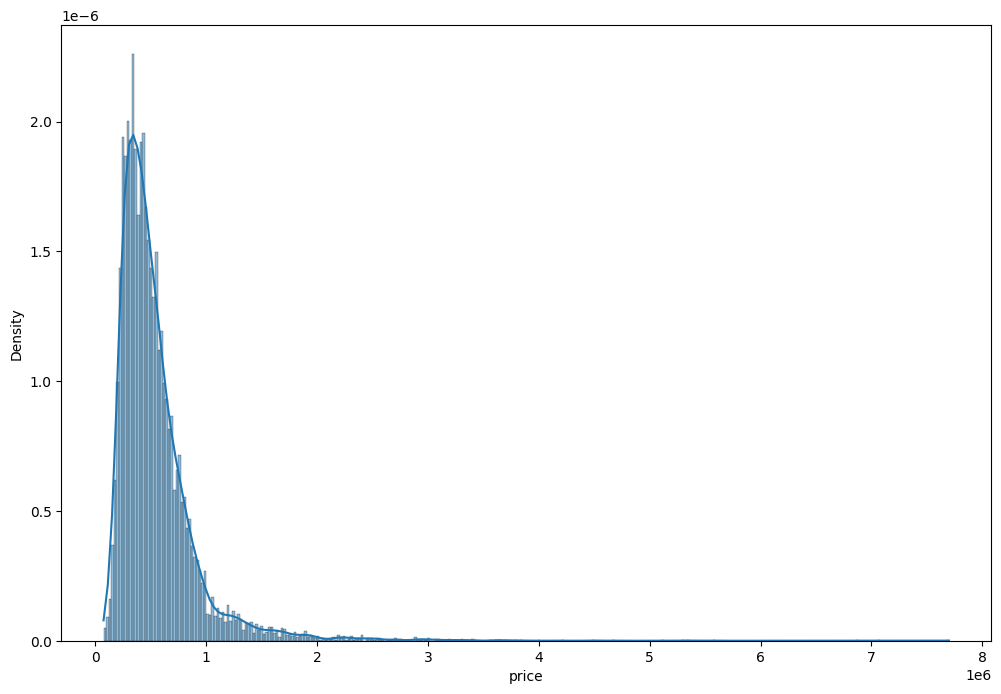

In [165]:
#przykładowe rozwiązanie
fig,axes=plt.subplots(nrows=1,ncols=1,figsize=(12,8))
sns.histplot(df['price'], kde=True, stat='density', label='price')

###### Wyrysować histogram powierzchni mieszkania - zmiennej objaśniającej (sqft_living)

In [166]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Tak samo jak poprzedni histogram — skorzystaj z `sns.histplot()`. Tym razem zmienna to `sqft_living`.

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

<Axes: xlabel='sqft_living', ylabel='Count'>

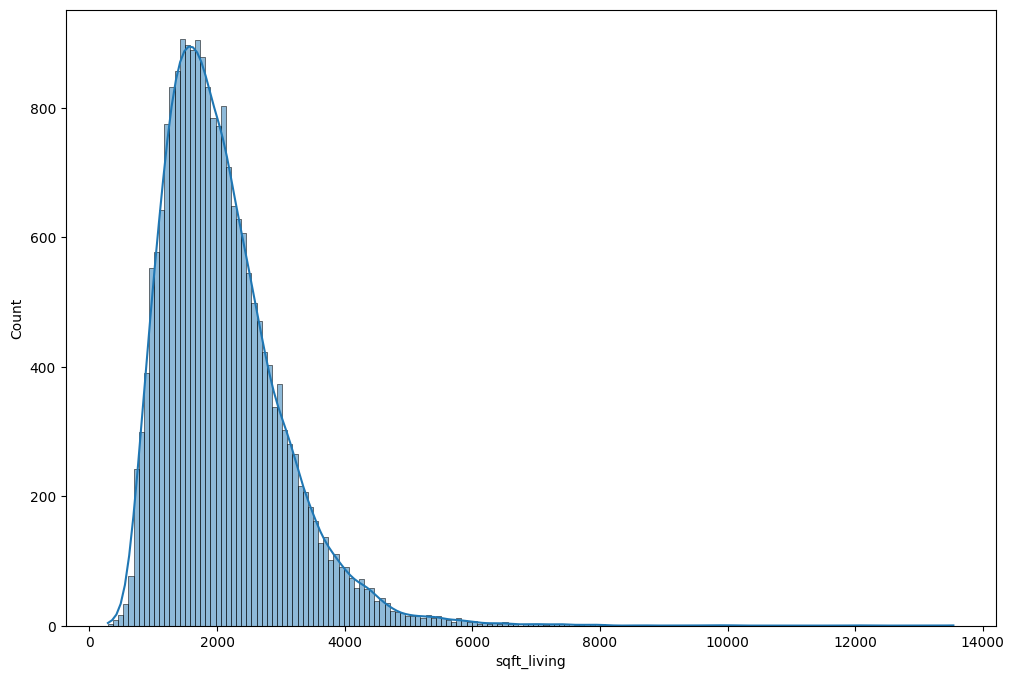

In [167]:
#przykładowe rozwiązanie
fig,axes=plt.subplots(nrows=1,ncols=1,figsize=(12,8))
sns.histplot(df['sqft_living'], kde=True)

###### Wyrysować wykres słupkowy liczby sypialni - zmiennej objaśniającej (bedrooms)

In [168]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Nie potrzebujesz średniej — chcesz policzyć ile razy pojawia się każda wartość.
Skorzystaj z `sns.countplot()`. Pamiętaj o parametrach `data=df` i `x='bedrooms'`.

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

<Axes: xlabel='bedrooms', ylabel='count'>

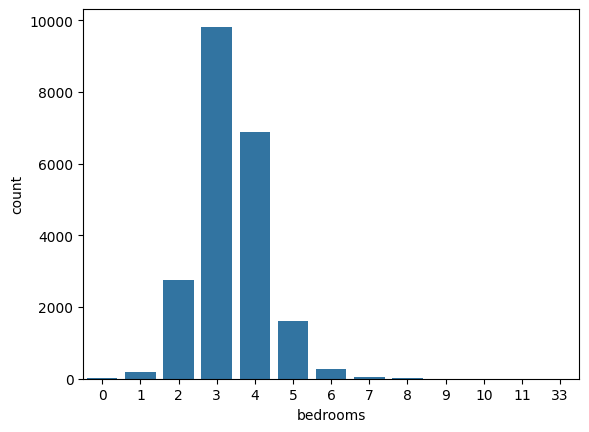

In [169]:
#przykładowe rozwiązanie
sns.countplot(data=df, x='bedrooms')

### Czyszczenie danych — usuwamy oczywisty błąd

Na wykresie widać pojedynczy słupek dla **33 sypialni** — to ewidentna literówka lub błąd przy wprowadzaniu danych. Gdybyśmy mieli dostęp do eksperta domenowego (np. agenta nieruchomości lub właściciela bazy), być może pozwoliłby nam ręcznie poprawić wartość na **3** — co byłoby sensowne w kontekście reszty danych. Bez takiej weryfikacji bezpieczniej jest po prostu **usunąć cały wiersz**.

Tego rodzaju decyzje — czy poprawiać, czy usuwać, jak dużo danych możemy sobie pozwolić odrzucić — to chleb powszedni pracy z danymi w praktyce.

In [170]:
# Data cleaning — usuwamy wiersz z 33 sypialniami (ewidentny błąd w danych)
# Gdybyśmy mieli kontakt z ekspertem od danych, mogli by nam pozwolić
# ręcznie zmienić wartość na 3 — ale bez takiej weryfikacji lepiej usunąć cały wiersz
print(f"Wierszy przed czyszczeniem: {len(df)}")
df = df[df["bedrooms"] != 33].reset_index(drop=True)
print(f"Wierszy po czyszczeniu:    {len(df)}")
print(f"Usunięto {21613 - len(df)} wiersz(y)")

Wierszy przed czyszczeniem: 21613
Wierszy po czyszczeniu:    21612
Usunięto 1 wiersz(y)


### Dodatkowe wizualizacje

Zależność ceny od powierzchni mieszkania - widać, że czym większe mieszkanie tym większa cena

<Axes: title={'center': 'house prices by sqft_living'}, xlabel='sqft_living', ylabel='house prices'>

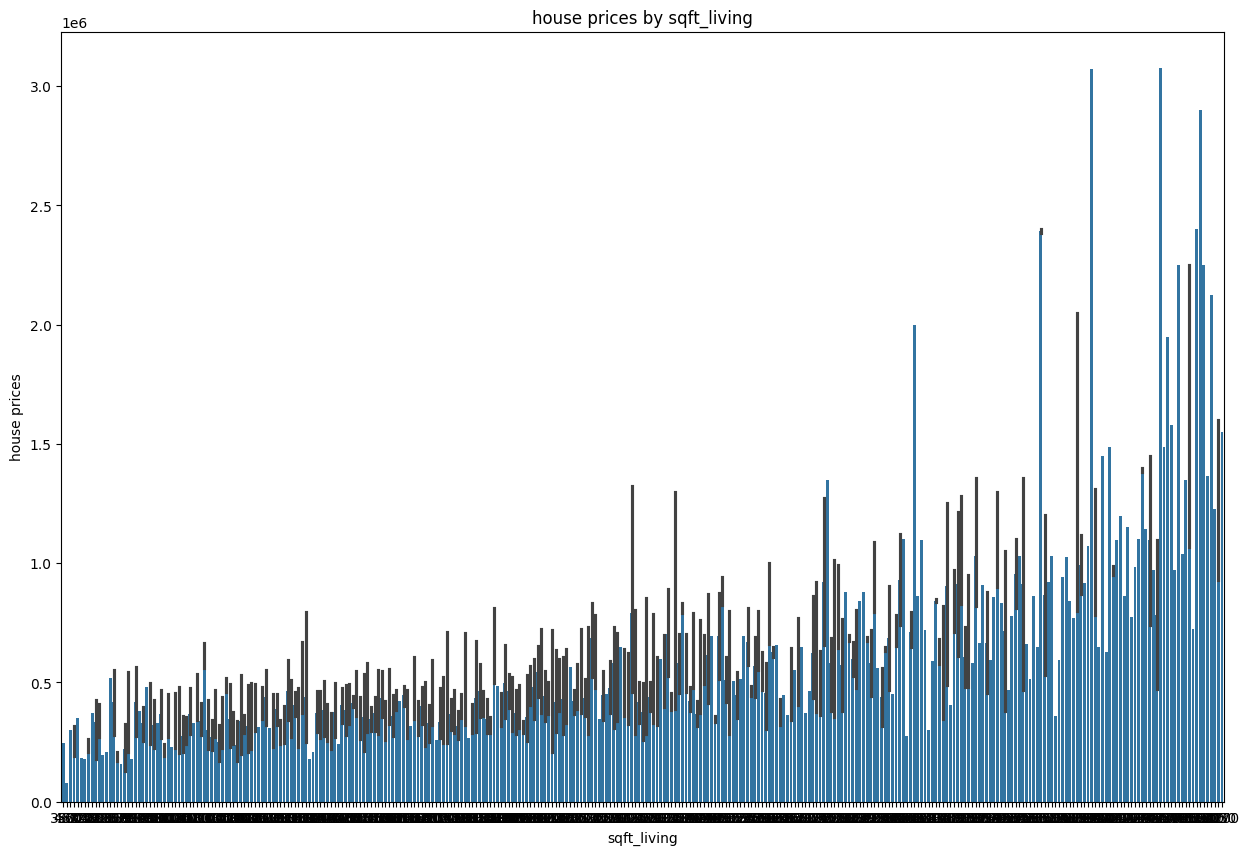

In [171]:
fig,axes=plt.subplots(nrows=1,ncols=1,figsize=(15,10))
plt.title("house prices by sqft_living")
plt.xlabel('sqft_living')
plt.ylabel('house prices')
sns.barplot(x='sqft_living',y='price',data=df.iloc[:1000,:])

### Korelacja ≠ przyczynowość

Zaraz zobaczymy macierz korelacji. Zanim ją zinterpretujesz, zapamiętaj:

**Korelacja** mówi tylko o tym, że dwie zmienne **poruszają się razem**. Nie mówi o tym, że jedna **powoduje** drugą.

Klasyczne przykłady absurdalnych korelacji:
- Sprzedaż lodów koreluje z liczbą utonięć (obie rosną latem — wspólna przyczyna to pogoda).
- Liczba filmów z Nicolasem Cage'em koreluje z liczbą utonięć w basenie (przypadek).

W naszym zbiorze: jeśli `sqft_living` i `sqft_above` są mocno skorelowane, to nie znaczy, że jedno powoduje drugie — po prostu mierzą częściowo tę samą rzecz.

**Wniosek praktyczny:** przy wyborze cech do modelu unikamy mocno skorelowanych zmiennych między sobą (problem **multicollinearity**). Szukamy za to cech mocno skorelowanych z **targetem** (`price`).



Wartości korelacji liniowej między zmiennymi - mogą służyć do wyboru zmiennych objaśniających użytych do modelu **regresji liniowej**

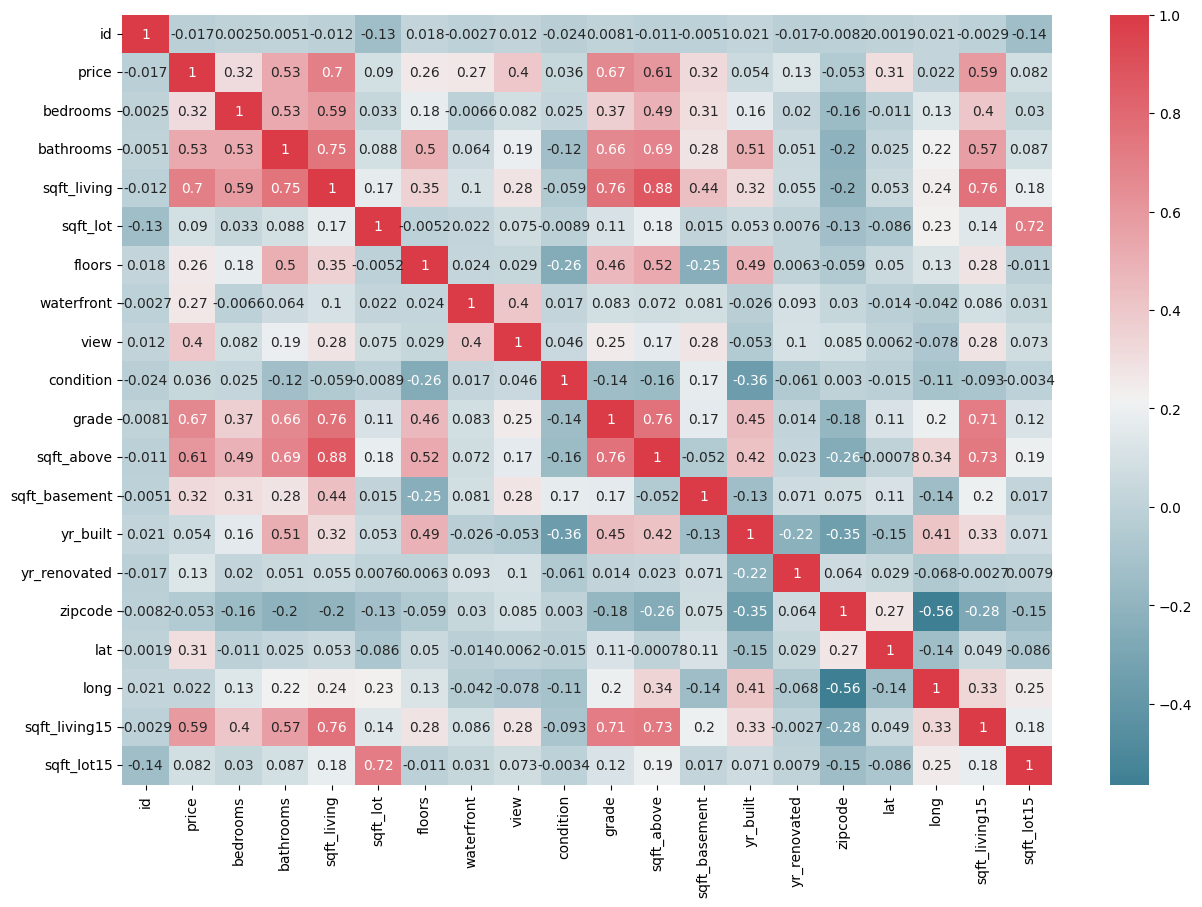

In [172]:
def correlation_heatmap(df1):
    _,ax=plt.subplots(figsize=(15,10))
    colormap=sns.diverging_palette(220,10,as_cmap=True)
    sns.heatmap(df1.select_dtypes(include="number").corr(), annot=True, cmap=colormap)
    
correlation_heatmap(df)

Wykresy pudełkowe dla kilku **zmiennych kategorycznych**

<Axes: xlabel='bathrooms', ylabel='price'>

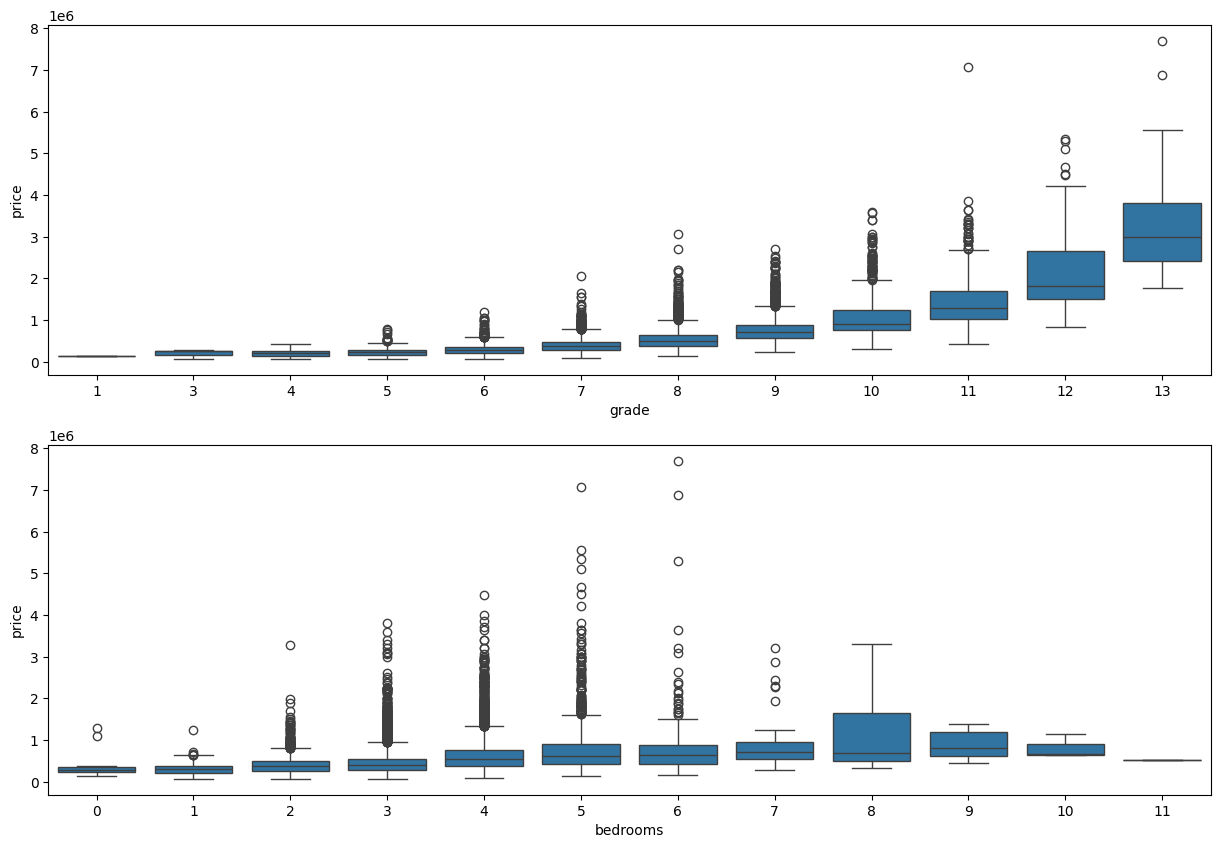

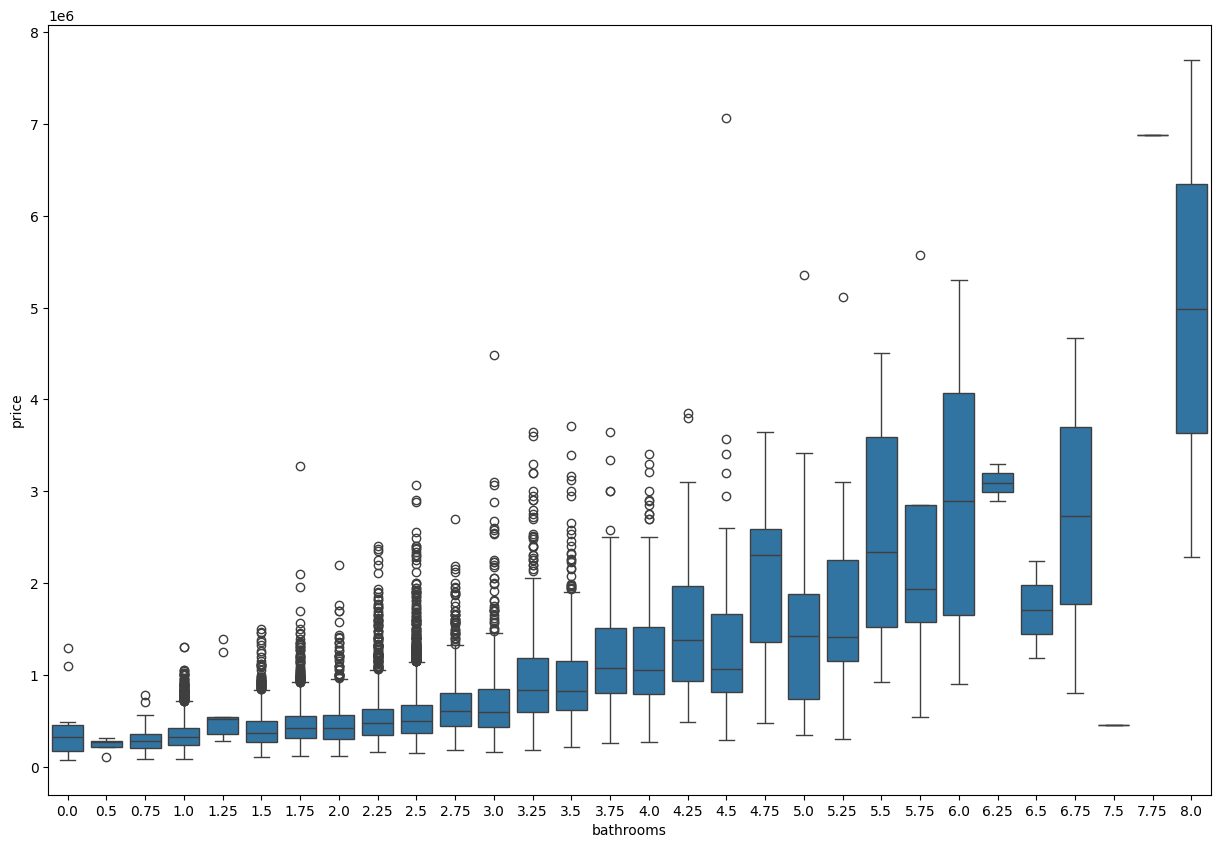

In [173]:
fig,ax=plt.subplots(2,1,figsize=(15,10))
sns.boxplot(x=df['grade'],y=df['price'],ax=ax[0])
sns.boxplot(x=df['bedrooms'],y=df['price'],ax=ax[1])
_ , axes = plt.subplots(1, 1, figsize=(15,10))
sns.boxplot(x=df['bathrooms'],y=df['price'])

> 💡 **Ciekawostka — EDA w jednej linii:** Istnieją biblioteki jak `ydata-profiling` czy `SweetViz`, które generują pełny raport HTML (histogramy, korelacje, brakujące wartości) jednym wywołaniem. W praktyce warto je znać, choć wymagają osobnej instalacji i mogą mieć ograniczenia zależności od wersji środowiska.

---

## Intuicja: co to znaczy "najlepsza linia"?

Zanim wyprowadzimy wzory, pomyśl intuicyjnie.

Masz chmurę punktów: na osi X powierzchnia mieszkania, na osi Y cena. Chcesz narysować **jedną linię prostą**, która "najlepiej" przechodzi przez te punkty. Ale co to znaczy "najlepiej"?

**Pomysł 1:** Linia, która przechodzi przez jak najwięcej punktów.
- ❌ Problem: w prawdziwych danych punkty są rozrzucone. Zwykle przez żaden punkt nie przejdzie dokładnie żadna linia.

**Pomysł 2:** Linia, której **suma odległości** do wszystkich punktów jest najmniejsza.
- Problem: odległości na plus i na minus się znoszą. Linia przechodząca przez średnią ma sumę 0.

**Pomysł 3:** Linia, której suma **kwadratów odległości** jest najmniejsza (MSE — *mean squared error*).
- To właśnie jest regresja liniowa metodą najmniejszych kwadratów.

**Dlaczego kwadraty, a nie np. wartości bezwzględne?**

1. **Matematycznie wygodne** — funkcja kwadratowa jest gładka (ma pochodną wszędzie), a wartość bezwzględna ma "dziób" w zerze.
2. **Analityczne rozwiązanie** — dla MSE istnieje prosty wzór na optymalne parametry. Dla wartości bezwzględnej trzeba szukać iteracyjnie.
3. **Kara za duże błędy** — pomyłka o 10 zł jest "karana" 100 razy słabiej niż pomyłka o 100 zł. To często pożądane.
4. **Interpretacja probabilistyczna** — MSE odpowiada założeniu, że szum w danych ma rozkład normalny (Gauss).

> **Ciekawostka:** metoda najmniejszych kwadratów została wymyślona przez **Gaussa** około 1795 roku (miał wtedy 18 lat), gdy próbował wyznaczyć orbitę planetoidy Ceres. Ponad 200 lat później nadal jej używamy.



In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 5 — Najlepsza linia — intuicja</b>"))
display(Audio("https://drive.google.com/uc?id=1PAK3zLEHxT1kytDn8meLYjR_AV2QYBPW"))

## Regresja liniowa - wersja 2D

In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 6 — Regresja 2D — wzory i implementacja</b>"))
display(Audio("https://drive.google.com/uc?id=1iW5R3MwedzYD9ClXNfOLuSqReCzlGh3a"))

W tej wersji będziemy używać tylko jednej zmiennej objaśniającej - powierzchni mieszkani (sqft_living) i będziemy starali się wypredykować cenę (price)

##### Wyrysywać wykres (2D) powierzchni i ceny

In [174]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Skorzystaj z `plt.scatter(x, y)`. Pamiętaj o `plt.xlabel()` i `plt.ylabel()` żeby opisać osie.

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Text(0, 0.5, 'price')

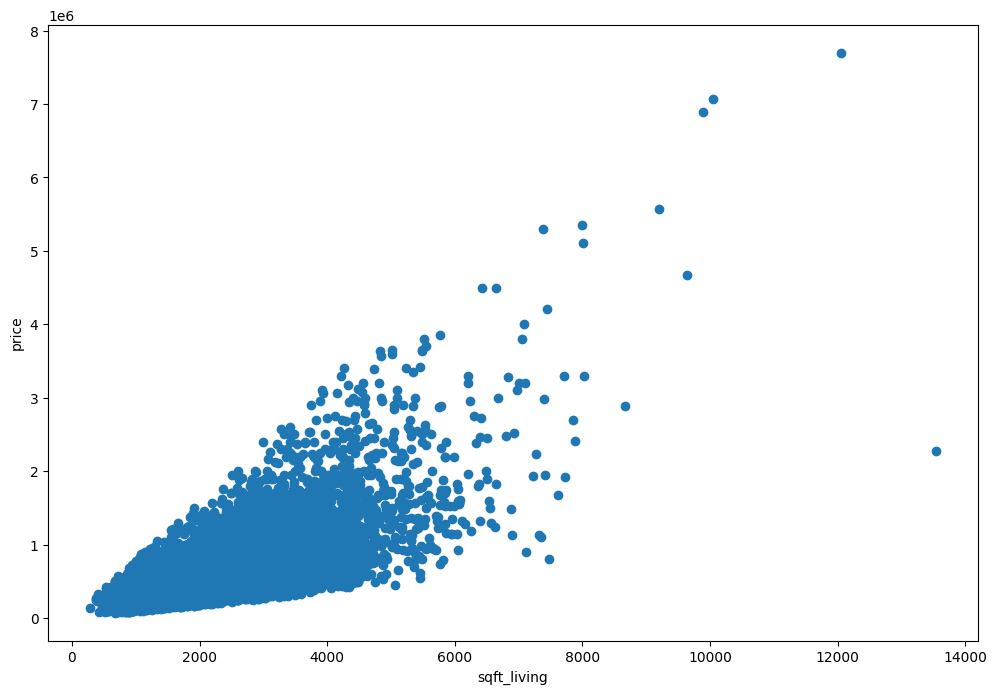

In [175]:
#przykładowe rozwiązanie
fig,axes=plt.subplots(nrows=1,ncols=1,figsize=(12,8))
plt.scatter(df['sqft_living'], df['price'])
plt.xlabel('sqft_living')
plt.ylabel('price')

###### Robocza funckja do rysowania Scatter-plot'a wraz z informacją o gęstości pomiarów


In [176]:
def scatter_with_density(data, x, y):
    x_name, y_name = x, y
    x = data[x]
    y = data[y]
    values = np.vstack([x, y])
    kernel = stats.gaussian_kde(values)(values)
    fig, ax = plt.subplots(figsize=(6, 6))
    sns.scatterplot(
        data=data,
        x=x_name,
        y=y_name,
        c=kernel,
        cmap="viridis",
        ax=ax,
    )

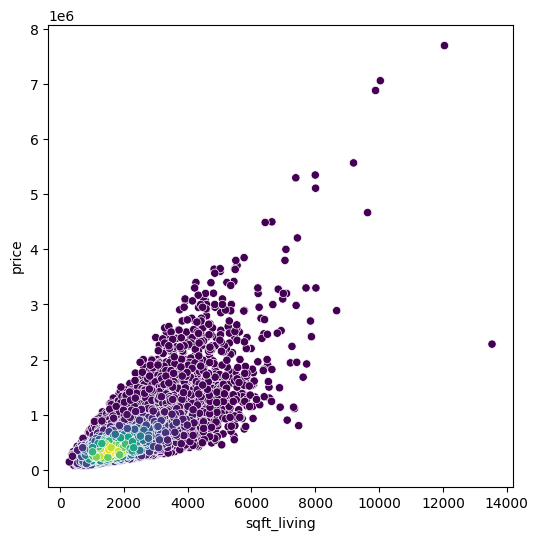

In [177]:
scatter_with_density(data=df, x='sqft_living', y='price')

<div style="background: #eef6ff; border-left: 4px solid #3b82f6; padding: 0.9em 1.2em; border-radius: 4px; margin: 0.8em 0;">

**Trenownie modelu**

**Kluczowa myśl:** cała "wiedza" modelu zawarta jest właśnie w tych dwóch liczbach — $a_0$ i $a_1$. Nic więcej. To właśnie parametry są tym, co model zapamiętuje po trenowaniu.

</div>


### Funkcja kosztu — serce uczenia maszynowego

Przeczytaj uważnie poniższą komórkę. To kluczowy moment:

- Mamy **model** z parametrami $a_0, a_1$ (wiedza modelu "mieszka" właśnie w tych dwóch liczbach).
- Dla każdego mieszkania model **przewiduje** cenę: $\hat{y} = a_1 \cdot x + a_0$.
- **Błąd** dla jednego mieszkania to $\hat{y} - y$ (różnica między predykcją a prawdą).
- **Funkcja kosztu** $J$ to uśredniony kwadrat tych błędów — **jedna liczba**, która mówi, jak źle nasz model radzi sobie na całych danych.

**Cel uczenia:** znaleźć takie $a_0, a_1$, dla których $J$ jest **najmniejsze**. Każdy model uczenia maszynowego — od regresji liniowej po GPT — sprowadza się do minimalizacji jakiejś funkcji kosztu. Różni się tylko to, jaka to funkcja i jak ją minimalizujemy.



Przypomnienie z liceum: liniowy model wygląda następująco: $$\hat{y} = a \cdot x + b$$ W postaci bardziej ogólnej (za chwilę będziemy używać wielomianów) : $$\hat{y} = a_1 \cdot x + a_0$$  $a_1$ oraz $a_0$ to **parametry** modelu - to miejsce gdzie znajduje się cała "wiedza" modelu.  Teraz zdefiniujmy funkcję kosztu - MSE (mean squared error): $$J = \frac{1}{n} \sum_{i=1}^{n} (\hat{y} - y)^2$$ Czym większa będzie różnica między $\hat{y}$ (czyli ceną predykowaną przez nasz model) a $y$ (czyli prawdziwą ceną) - tym większy będzie błąd/funkcja kosztu. To co chcemy zrobić to znaleźć minimum tej funckji. I tutaj z pomocą przychodzi analiza matematyczna oraz pochodne - musimy wyzerować pochodną tej funkcji. Przypomnienie pochodnych na przykładzie funkcji kwadratowej:

### Dlaczego pochodna = 0 daje minimum?

Jeśli kurs z analizy matematycznej Ci się zatarł — szybkie przypomnienie:

- Pochodna funkcji w danym punkcie to **nachylenie stycznej** do wykresu w tym punkcie.
- W **minimum lokalnym** wykres najpierw opada, potem rośnie → w samym dole nachylenie jest **zerowe** (styczna pozioma).
- Dla funkcji **kwadratowej** (parabola otwarta do góry) jest tylko jedno minimum i jest to minimum **globalne**.

Nasza funkcja kosztu $J(a_0, a_1)$ jest sumą kwadratów — czyli **paraboliczna** względem parametrów. Dlatego:

1. Ma dokładnie **jedno minimum**.
2. Możemy je znaleźć, przyrównując pochodne cząstkowe $\partial J / \partial a_0$ i $\partial J / \partial a_1$ do zera.
3. Powstaje układ dwóch równań z dwoma niewiadomymi — rozwiązalny "na kartce".

To jest **unikalna własność** regresji liniowej z MSE. Dla bardziej skomplikowanych modeli (np. sieci neuronowych) funkcja kosztu nie jest paraboliczna, ma wiele minimów lokalnych, i trzeba używać **gradient descent** (o którym usłyszysz na kolejnych zajęciach).



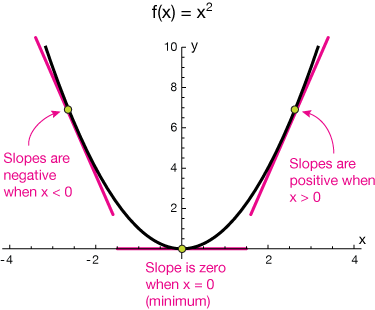

Po przyrównaniu pochodnej do zera możemy analitycznie wyliczyć wartości parametrów w zależności od y i x:
$$ a_1 = \frac{\sum (x-\bar{x})(y-\bar{y})}{\sum (x-\bar{x})^2} = \frac{\sum (xy) - n\bar{x}\bar{y}}{\sum x^2 - n\bar{x}\bar{x}} $$ $$ a_0 = \bar{y} - a_1\bar{x}$$ gdzie $\bar{x}$ to średnia ze zmiennej x a $\bar{y}$ to średnia ze zmiennej y

##### Proszę wyliczyć $a_0$ oraz $a_1$ na podstawie powyższych wzorów

In [178]:
x = df['sqft_living']
y = df['price']
n = len(x)

# proszę poniżej kontynuować kod

In [179]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Wzory masz podane powyżej — spróbuj przetłumaczyć je na numpy krok po kroku.

Przydatne funkcje: `np.mean()`, `np.sum()`.

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

In [180]:
#rozwiązanie

x_mean = np.mean(x)
y_mean = np.mean(y)
num = np.sum(x*y) - n*x_mean*y_mean
denom = np.sum(x*x) - n*x_mean*x_mean

a1 = num/denom
a0 = y_mean-a1*x_mean

###### Sprawdzenie współczynników

In [181]:
print(f"Współczynnik a1 wynosi {a1:.3f}, zaś a0 wynosi {a0:.3f}")

Współczynnik a1 wynosi 280.629, zaś a0 wynosi -43603.350


Czyli nasz model wytrenowany na danych uczących powinien wyglądać następująco: <br><br> $$\hat{y} = 280.629 \cdot x - 43603.350$$

### Dlaczego zamykamy model w klasę?

Do tej pory $a_0$ i $a_1$ to były po prostu dwie zmienne. Ale zawodowo prawie **nigdy** nie używa się modeli w ten sposób. Zamiast tego pakujemy je w **klasę** (obiekt) z dwiema metodami:

- **`fit(X, y)`** — uczy model na danych treningowych (zapisuje parametry wewnątrz obiektu).
- **`predict(X)`** — używa wyuczonych parametrów do przewidywania dla nowych danych.

Dlaczego tak?

1. **Standard scikit-learn** — wszystkie modele w `sklearn` (a jest ich setki: regresje, drzewa, lasy, SVM, ...) mają dokładnie takie API. Jak nauczysz się jednego, znasz wszystkie.
2. **Wymienialność** — dzięki wspólnemu interfejsowi możesz w pipeline podmienić `LinearRegression()` na `RandomForest()` zmieniając jedną linijkę.
3. **Enkapsulacja** — parametry modelu (wiedza) żyją wewnątrz obiektu, nie latają luzem po notebooku.
4. **Stan** — obiekt "pamięta", czy był już nauczony. Nie da się wywołać `predict` przed `fit`.



In [182]:
class LinearModel():
    def __init__(self, a0, a1):
        self.a0 = a0
        self.a1 = a1
        
    def __call__(self, x_iterable):
        try:
            return [self.a1*x + self.a0 for x in x_iterable]
        except TypeError:
            return self.a1*x_iterable + self.a0

In [183]:
try:
    # Tutaj wpisz swój kod — jakie zmienne musi przyjąć LinearModel?
    linear_model = LinearModel(None, None)
    if linear_model.a0 is None or linear_model.a1 is None:
        raise ValueError
except (NameError, ValueError):
    print(f"{bcolors.BOLD}{bcolors.FAIL}Proszę sprawdzić czy zostały przypisane wartości do parametrów a0 i a1{bcolors.ENDC}")
    linear_model = None
else:
    pred=linear_model(x)
    mean_squared_error=metrics.mean_squared_error(y,pred)
    print('Root mean squared error (RMSE)', round(np.sqrt(mean_squared_error),2))

Proszę sprawdzić czy zostały przypisane wartości do parametrów a0 i a1


###### <span style="color: #c17f24;">💡 Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Masz już obliczone `a0` i `a1` powyżej — po prostu podaj je jako argumenty:

```python
linear_model = LinearModel(???, ???)
```
Zamień `???` na właściwe nazwy zmiennych.


###### <span style="color: #5a8a6a;">✅ Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

```python
linear_model = LinearModel(a0, a1)
```


In [184]:
try:
    # Tutaj wpisz swój kod — podaj obliczone wcześniej a0 i a1
    linear_model = LinearModel(a0, a1)
    if linear_model.a0 is None or linear_model.a1 is None:
        raise ValueError
except (NameError, ValueError):
    print(f"{bcolors.BOLD}{bcolors.FAIL}Proszę sprawdzić czy zostały przypisane wartości do parametrów a0 i a1{bcolors.ENDC}")
    linear_model = None
else:
    pred=linear_model(x)
    mean_squared_error=metrics.mean_squared_error(y,pred)
    print('Root mean squared error (RMSE)', round(np.sqrt(mean_squared_error),2))

Root mean squared error (RMSE) 261442.2


##### 

<span style="font-family:Monospace">Root mean squared error (RMSE) 261442.2</span>

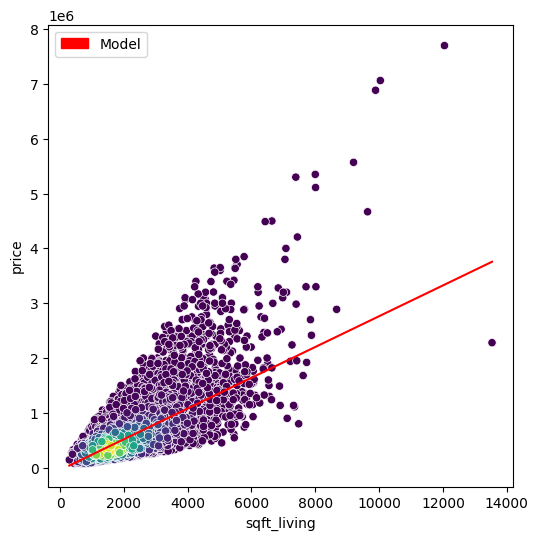

In [185]:
if linear_model is None:
    print(f"{bcolors.BOLD}{bcolors.FAIL}Najpierw wylicz a0 i a1 w komórce powyżej{bcolors.ENDC}")
else:
    x_lin = np.linspace(min(x), max(x))
    y_lin = linear_model(x_lin)

    scatter_with_density(data=df, x='sqft_living', y='price')
    plt.plot(x_lin, y_lin, color='r')

    red_patch = mpatches.Patch(color='red', label='Model')
    plt.legend(handles=[red_patch])

##### Zadanie dodatkowe - przekopiować powyższą implementację klasy LinearModel i dodać do niej metodę .fit , która dla nowych danych uczących wyznaczy nowe parametry modelu liniowego, oraz zmienić metodą __call__ na predict

In [186]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Skopiuj klasę `LinearModel` i wprowadź 3 zmiany:

1. W `__init__` ustaw `self.a0 = None`, `self.a1 = None`
2. Dodaj metodę `fit(self, x, y)` — przenieś do niej obliczenia `a0` i `a1` z poprzedniego zadania, zapisując wyniki jako `self.a0` i `self.a1`
3. Zmień metodę `__call__` na `predict` i dodaj sprawdzenie czy `self.a0 is not None`

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

In [187]:
# rozwiązanie
from sklearn.exceptions import NotFittedError

class LinearModel():
    def __init__(self):
        self.a0 = None
        self.a1 = None
    
    def fit(self, x, y):
        n = len(x)
        x_mean = np.mean(x)
        y_mean = np.mean(y)
        num = np.sum(x*y) - n*x_mean*y_mean
        denom = np.sum(x*x) - n*x_mean*x_mean

        self.a1 = num/denom
        self.a0 = y_mean-self.a1*x_mean
            
    def predict(self, x_iterable):
        if self.a0 is None or self.a1 is None:
            raise NotFittedError 
        try:
            return [self.a1*x + self.a0 for x in x_iterable]
        except TypeError:
            return self.a1*x_iterable + self.a0
    

##### Model jako klasa — siła interfejsu fit/predict

Skoro model jest klasą z metodami `fit` i `predict`, możemy w jednej linijce wytrenować zupełnie nowy model na innych danych — bez żadnych zmian w reszcie kodu.

Poniżej trenujemy dwa modele niezależnie: jeden przewiduje cenę na podstawie **powierzchni** (`sqft_living`), drugi na podstawie **liczby sypialni** (`bedrooms`). Każdy to osobny obiekt z własną wiedzą (parametrami `a0`, `a1`), ale oba korzystają z identycznego interfejsu.

Dokładnie tak samo działa **scikit-learn** — najpopularniejsza biblioteka ML w Pythonie. Każdy model (regresja liniowa, drzewo decyzyjne, las losowy, SVM…) ma `fit` i `predict`. Jak nauczysz się jednego, wiesz jak działają wszystkie.

In [188]:
linear_model_space = LinearModel()
linear_model_space.fit(df['sqft_living'], df['price'])
result = linear_model_space.predict([1000, 1250])
print(f"Wypredykowane ceny dla wartości sqft_living 1000 - {result[0]:.3f}, oraz dla wartości 1250 - {result[1]:.3f}")

Wypredykowane ceny dla wartości sqft_living 1000 - 237025.993, oraz dla wartości 1250 - 307183.329


<span style="font-family:Monospace">Wypredykowane ceny dla wartości sqft_living 1000 - 237025.993, oraz dla wartości 1250 - 307183.329</span>

<div style="background: #eef6ff; border-left: 4px solid #3b82f6; padding: 0.9em 1.2em; border-radius: 4px; margin: 0.8em 0;">

**Dlaczego warto było to robić?**

Właśnie skorzystaliśmy z tego, co zbudowaliśmy. Żeby wytrenować model na zupełnie innej zmiennej — liczbie sypialni zamiast powierzchni — wystarczyła **jedna linijka** z nowymi danymi. Reszta kodu: identyczna. Oba modele działają niezależnie, każdy z własną wiedzą zamkniętą w parametrach `a0` i `a1`.

To jest właśnie siła interfejsu `fit` / `predict` — tego samego, którego używa scikit-learn.

</div>

In [189]:
linear_model_bedroom = LinearModel()
linear_model_bedroom.fit(df['bedrooms'], df['price'])
result = linear_model_bedroom.predict([4, 3, 2])
print(f"Wypredykowane ceny dla wartości bedrooms 4 - {result[0]:.3f}, 3 - {result[1]:.3f} oraz 2 - {result[2]:.3f}")

Wypredykowane ceny dla wartości bedrooms 4 - 620506.003, 3 - 492958.434 oraz 2 - 365410.865


<span style="font-family:Monospace">Wypredykowane ceny dla wartości bedrooms 4 - 620506.003, 3 - 492958.434 oraz 2 - 365410.865</span>

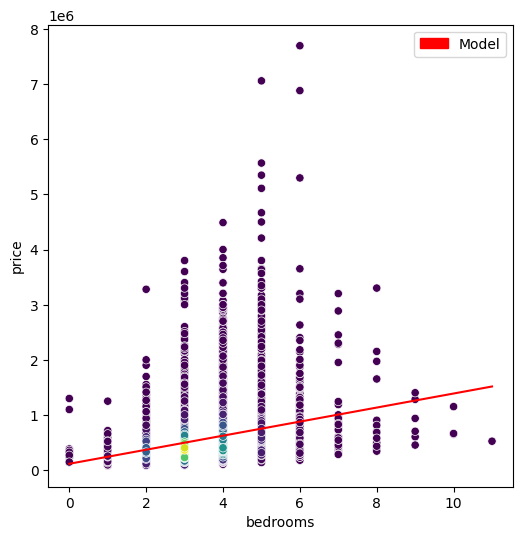

In [190]:
if linear_model_bedroom is None:
    print(f"{bcolors.BOLD}{bcolors.FAIL}Najpierw zbuduj model linear_model_bedroom powyżej{bcolors.ENDC}")
else:
    x_bed = df['bedrooms']
    x_lin_bed = np.linspace(min(x_bed), max(x_bed))
    y_lin_bed = linear_model_bedroom.predict(x_lin_bed)

    scatter_with_density(data=df, x='bedrooms', y='price')
    plt.plot(x_lin_bed, y_lin_bed, color='r')

    red_patch = mpatches.Patch(color='red', label='Model')
    plt.legend(handles=[red_patch])

---

## Z 2D do 3D — dlaczego więcej zmiennych to lepszy model?

W wersji 2D model przewidywał cenę **tylko** na podstawie powierzchni. Ale cena zależy od wielu rzeczy: liczby sypialni, lokalizacji, wieku budynku, widoku, stanu łazienek... Im więcej istotnych informacji damy modelowi, tym dokładniejsza predykcja.

**Geometria:**
- Z **jedną** zmienną objaśniającą → dopasowujemy **linię** w 2D.
- Z **dwiema** zmiennymi → dopasowujemy **płaszczyznę** w 3D.
- Z **$n$** zmiennymi → dopasowujemy **hiperpłaszczyznę** w $(n+1)$-wymiarowej przestrzeni.

Ta ostatnia trudniej jest sobie wyobrazić, ale matematyka jest **identyczna** dla każdego $n$. Właśnie dlatego zaraz przejdziemy na zapis macierzowy — jeden wzór działa dla dowolnej liczby cech.

**Uwaga — przekleństwo wymiarowości:**
Więcej cech ≠ zawsze lepszy model. Jeśli dorzucisz kolumnę z zupełnie losowym szumem, model spróbuje dopasować się i do niej, co zwykle pogarsza jego zdolność generalizacji. O wyborze cech (*feature selection*) będzie osobny wykład.



In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 7 — Z 2D do 3D — więcej zmiennych</b>"))
display(Audio("https://drive.google.com/uc?id=1LUxv4r18vuAfWv62jjP9_1E7pGMTW1BJ"))

## Regresja liniowa - wersja 3D

In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 8 — Regresja 3D — notacja macierzowa</b>"))
display(Audio("https://drive.google.com/uc?id=1fkhSUO3DOiMDRN8d239vnhrWaoe-XmBd"))

W tej wersji będziemy używać dwóch zmiennych objaśniających - powierzchni mieszkani (sqft_living) oraz liczby sypialni (bedrooms) i będziemy starali się wypredykować cenę (price)

###### Zadanie dodatkowe - proszę wyrysować wykres 3D dwóch zmiennych objaśniających i zmiennej objaśnianej (można też użyć rozwiązania umieszczonego niżej). Można ograniczyć się tylko do pierwych 100 lub 1000 wierszy z tabeli danych aby nie czekać długo na wykonanie funkcji

In [191]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Skorzystaj z `px.scatter_3d()`. Podaj `data_frame=df_small` i wskaż kolumny:
`x='sqft_living'`, `y='bedrooms'`, `z='price'`.

Pamiętaj żeby ograniczyć dane np. `df_small = df.iloc[:100,:]` — bez tego wykres będzie się długo ładował.

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

In [192]:
# przykładowe rozwiązanie

#pierwsze 1000 wierszy
df_small = df.iloc[:1000,:]

fig = px.scatter_3d(df_small, x='sqft_living', y='bedrooms', z='price')

fig.update_layout(margin=dict(l=0, r=0, b=0, t=0))

### Po co nam notacja macierzowa?

Gdybyśmy dla każdej zmiennej pisali osobne $a_0, a_1, a_2, ...$, wzór na $n$ cech byłby ogromny. Notacja macierzowa:

$$\hat{y} = X \cdot w$$

**jedno wyrażenie**, działa dla dowolnej liczby cech $n$ i dowolnej liczby przykładów $m$. W numpy zapiszemy to jako `X @ w` — jeden znak!

**Intuicja $X^T X$:**

Wzór $w = (X^T X)^{-1} X^T Y$ wygląda magicznie, ale ma prostą interpretację:

- $X^T X$ to **macierz Grama** — zawiera informacje o tym, jak cechy korelują ze sobą.
- $X^T Y$ — informacja o tym, jak cechy korelują z targetem.
- Odwracamy pierwszą i mnożymy przez drugą → to jest analityczne rozwiązanie równania $X^T X w = X^T Y$ (tzw. **równania normalne**).

**Co jeśli $X^T X$ jest nieodwracalna?**

To się dzieje, gdy **kolumny $X$ są liniowo zależne** (np. `sqft_living` = `sqft_above` + `sqft_basement`). Wtedy trzeba użyć **pseudoodwrotności** (`np.linalg.pinv`) lub **regularyzacji** (Ridge, Lasso — też na kolejnych zajęciach).



#### **Szybkie przypomnienie mnożenia macierzowego**

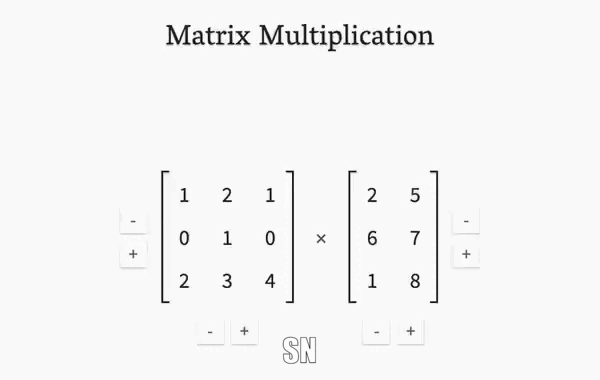

##### Trenowanie modelu

Liniowy model dla więcej niż jednej zmiennej objaśniającej zapiszemy w postaci macierzowej: $$\hat{y} = w^T x + b$$ Jednak w tej sytuacji $w$ oraz $b$ mogą być macierzami: $$\hat{y} = \begin{bmatrix}
x_1\\
x_2
\end{bmatrix}^T  \begin{bmatrix}
w_1\\
w_2
\end{bmatrix} + \begin{bmatrix}
b
\end{bmatrix}$$ P.S. Jeśli chcielibyśmy predykować także inną zmienną to również y byłby macierzą. <br> Możemy napisać to w bardziej skondensowanej formie gdzie włączymy parametr $b$ do macierzy $w$ (proszę zwrócić uwagę na liczbę 1 włączoną do macierzy x):
$$\hat{y} = \begin{bmatrix}
\textbf{1}\\
x_1\\
x_2
\end{bmatrix}^T  \begin{bmatrix}
w_0\\
w_1\\
w_2
\end{bmatrix}$$
Macierz $w$ wraz z wszystkimi jej wartościami to **parametry** modelu - to miejsce gdzie znajduje się cała "wiedza" modelu.  Teraz zdefiniujmy funkcję kosztu - MSE (mean squared error): $$J = \frac{1}{n} \sum_{i=1}^{n} (\hat{y} - y)^2$$ Czym większa będzie różnica między $\hat{y}$ (czyli ceną predykowaną przez nasz model) a $y$ (czyli prawdziwą ceną) - tym większy będzie błąd/funkcja kosztu. To co chcemy zrobić to znaleźć minimum tej funckji. I tutaj z pomocą przychodzi analiza matematyczna oraz pochodne - musimy wyzerować pochodną tej funkcji. Przypomnienie pochodnych na przykładzie funkcji kwadratowej:

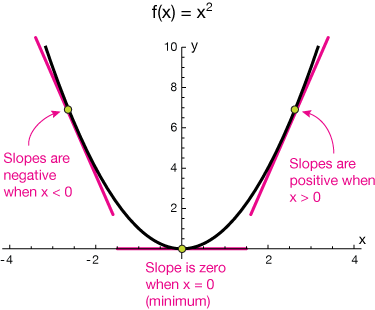

Po przyrównaniu pochodnej do zera możemy analitycznie wyliczyć wartości parametrów w zależności od y i x:
$$ w = (X^TX)^{-1}X^TY $$

##### Proszę wyliczyć macierz $w$ na podstawie powyższego wzoru 

przydatne funkcje oraz notacje: <br>
**@** - mnożenie macierzowe<br>
**X.T** - transpozycja macierzy (jeśli X jest macierzą) <br>
**np.linalg.inv** - funkcja z biblioteki numpy do odwracania macierzy

In [193]:
X_org = df[['sqft_living', 'bedrooms']].to_numpy()
# dodajmy kolumnę samych jedynek do x
X_shape = list(X_org.shape)
X_shape[-1] = 1
X = np.concatenate([np.ones(X_shape), X_org], axis=-1)

Y = df['price'].to_numpy()
print(f"Wymiar X to {X.shape}, zaś Y to {Y.shape}")
# proszę poniżej kontynuować kod

Wymiar X to (21612, 3), zaś Y to (21612,)


In [194]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Przetłumacz wzór $w = (X^TX)^{-1}X^TY$ na Python krok po kroku:

- `X.T` → transpozycja macierzy
- `@` → mnożenie macierzowe  
- `np.linalg.inv(...)` → odwrócenie macierzy

Spróbuj złożyć to w jedną linię kodu.

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

In [195]:
# rozwiązanie
w = np.linalg.inv(X.T @ X) @ X.T @ Y
#https://aunnnn.github.io/ml-tutorial/html/blog_content/linear_regression/linear_regression_tutorial.html

##### 

In [196]:
w

array([ 90033.63761138,    316.91809263, -62061.59387133])

<span style="font-family:Monospace">array([ 90033.63761138,    316.91809263, -62061.59387133])</span>

###### Zbudowanie prostej klasy

In [197]:
class LinearModelMulti():
    def __init__(self, w):
        self.w = w
        
    def __call__(self, X):
        X = np.array(X)
        if isinstance(X, np.ndarray) and len(X.shape)==1:
            X = X.reshape(1,-1)
        X_shape = list(X.shape)
        X_shape[-1] = 1
        X = np.concatenate([np.ones(X_shape), X], axis=-1)
        return X @ self.w

In [198]:
try:
    # Tutaj wpisz swój kod — jaka zmienna powinna być podana w ramach inizjalizacji klasy LinerModelMulti?
    linear_model = LinearModelMulti(None)
    if linear_model.w is None:
        raise ValueError
except (NameError, ValueError):
    print(f"{bcolors.BOLD}{bcolors.FAIL}Proszę sprawdzić czy została przypisana wartość do parametru w{bcolors.ENDC}")
    linear_model = None
else:
    result = linear_model(X_org[0:5,:])
    strFormat = len(result) * '{:0.3f} '
    formatted_results = strFormat.format(*result)
    print(f"Dla pierwszych 4 wierszy predykujemy następujące ceny: [{formatted_results}]")

Proszę sprawdzić czy została przypisana wartość do parametru w


###### <span style="color: #c17f24;">💡 Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Masz już obliczoną macierz `w` powyżej — podaj ją jako argument:

```python
linear_model = LinearModelMulti(???)
```
Zamień `???` na właściwą nazwę zmiennej.


###### <span style="color: #5a8a6a;">✅ Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

```python
linear_model = LinearModelMulti(w)
```


In [199]:
try:
    # Tutaj wpisz swój kod — podaj obliczoną wcześniej macierz w
    linear_model = LinearModelMulti(w)
    if linear_model.w is None:
        raise ValueError
except (NameError, ValueError):
    print(f"{bcolors.BOLD}{bcolors.FAIL}Proszę sprawdzić czy została przypisana wartość do parametru w{bcolors.ENDC}")
    linear_model = None
else:
    result = linear_model(X_org[0:5,:])
    strFormat = len(result) * '{:0.3f} '
    formatted_results = strFormat.format(*result)
    print(f"Dla pierwszych 4 wierszy predykujemy następujące ceny: [{formatted_results}]")


Dla pierwszych 4 wierszy predykujemy następujące ceny: [277812.205 718328.354 209937.381 462946.724 436271.252 ]


##### 

<span style="font-family:Monospace">Dla pierwszych 4 wierszy predykujemy następujące ceny: [277812.205 718328.354 209937.381 462946.724 436271.252 ]</span>

In [200]:
# Do wizualizacji weźmiemy tylko 100 pierwszych wierszy
df_small = df.iloc[:100,:]
X1 =df_small['sqft_living']
X2 =df_small['bedrooms']
Y =df_small['price']

X1_plane, X2_plane = np.meshgrid(X1, X2)
model_input = np.stack((X1_plane,X2_plane), axis=-1)
Y_plane = linear_model(model_input)

fig = go.Figure(data=[go.Surface(z=Y_plane, x=X1_plane, y=X2_plane, opacity=0.005), go.Scatter3d(x=X1, y=X2, z=Y, mode='markers')])

fig.update_layout(margin=dict(l=0, r=0, b=0, t=0))

##### Zadanie dodatkowe - przekopiować powyższą implementację klasy LinearModelMulti i dodać do niej metodę .fit , która dla nowych danych uczących wyznaczy nowe parametry modelu liniowego, oraz zmienić metodą __call__ na predict

In [201]:
# Tutaj wpisz swój kod


###### <span style="color: #c17f24;">Podpowiedź</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

Wzoruj się na istniejącej klasie `LinearModelMulti` powyżej. W metodzie `fit(self, X, Y)`:

1. `X = np.array(X)`
2. Dodaj kolumnę jedynek tak jak w komórce wyżej: `np.concatenate([np.ones(...), X], axis=-1)`
3. Oblicz `self.w` wzorem z poprzedniego zadania

W metodzie `predict` sprawdź czy `self.w is not None` zanim policzysz wynik.

###### <span style="color: #5a8a6a;">Rozwiązanie</span> <span style="color: #999; font-weight: normal; font-size: 0.85em;">(kliknij aby rozwinąć)</span>

In [202]:
# przykładowe rozwiązanie
class LinearModelMulti():
    def __init__(self):
        self.w = None
        
    @staticmethod
    def stack_ones(X):
        X_shape = list(X.shape)
        X_shape[-1] = 1
        return np.concatenate([np.ones(X_shape), X], axis=-1)
        
    def fit(self, X, Y):
        X = np.array(X)
        X = self.stack_ones(X)
        Y = np.array(Y)
        self.w = np.linalg.inv(X.T @ X) @ X.T @ Y
        
    def predict(self, X):
        if self.w is None:
            raise NotFittedError 
        X = np.array(X)
        if isinstance(X, np.ndarray) and len(X.shape)==1:
            X = X.reshape(1,-1)
        X = self.stack_ones(X)
        return X @ self.w

##### Ten sam interfejs, więcej danych

Właśnie zaimplementowałeś `LinearModelMulti` z metodami `fit` i `predict`.
Siła tego interfejsu polega na tym, że możemy go wywołać z **dowolną liczbą zmiennych objaśniających** — bez żadnych zmian w reszcie kodu.

Poniżej trenujemy model na **dwóch** cechach jednocześnie: powierzchni (`sqft_living`) i liczbie sypialni (`bedrooms`). Model dostaje więcej informacji, więc powinien predykować dokładniej niż wcześniejszy model jednowymiarowy.

In [203]:
linear_model = LinearModelMulti()
linear_model.fit(df[['sqft_living', 'bedrooms']], df['price'])
linear_model.predict([[1050, 2], [2100, 4], [750, 3]])

array([298674.44713392, 507315.25665646, 141537.42547254])

<span style="font-family:Monospace">array([298674.44713392, 507315.25665646, 141537.42547254])</span>

---

## Wielomiany i overfitting — granice regresji liniowej

Ten rozdział zawiera **dwie wielkie idee** które warto uchwycić:

### 1. Regresja wielomianowa to *wciąż* regresja liniowa!

Brzmi dziwnie? Spójrz uważnie na wzór:

$$\hat{y} = a_k \cdot x^k + ... + a_2 \cdot x^2 + a_1 \cdot x + a_0$$

Model jest **nieliniowy względem $x$**, ale **liniowy względem parametrów $a_0, a_1, ..., a_k$**. A to parametry trenujemy! Dla algorytmu to jest dokładnie ten sam problem co wcześniej — tylko zamiast jednej cechy $x$, mamy cechy $[1, x, x^2, x^3, ..., x^k]$.

Ten trik nazywa się **feature engineering** (inżynieria cech). Zamiast zmieniać model, **transformujemy dane**, a model zostaje prosty.

### 2. Overfitting — im więcej potęg, tym... gorzej?

Intuicyjnie: więcej parametrów = bardziej elastyczny model = lepsze dopasowanie. Ale:

- Wielomian stopnia $k$ może **dokładnie** przejść przez $k+1$ punktów.
- Taka krzywa "pamięta" dane treningowe zamiast uczyć się **wzorca**.
- Na nowych danych (testowych) takie modele radzą sobie **fatalnie**.

To się nazywa **overfitting** (Kamil mówi: model "przytulił się" do danych uczących) — model nauczył się hałasu, a nie sygnału. Obraz, który zaraz zobaczysz, jest jednym z najważniejszych w całym uczeniu maszynowym.

**Jak walczyć z overfittingiem?** (spoiler kolejnego laboratorium)
- **Regularyzacja** (Ridge, Lasso) — karzemy model za duże parametry.
- **Więcej danych** — trudniej przepasować model, gdy punktów jest dużo.
- **Prostszy model** — ograniczamy stopień wielomianu.
- **Walidacja krzyżowa** — wybieramy stopień, który najlepiej generalizuje.



In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 9 — Wielomiany — kiedy linia nie wystarcza</b>"))
display(Audio("https://drive.google.com/uc?id=1vcgRMYvULL-lANJwKw6Gd186ozY8Tr7n"))

## Regresja wielomianowa oraz overfitting

In [ ]:
from IPython.display import Audio, display, HTML
display(HTML("<b>🎙️ Odcinek 10 — Overfitting — eksperymenty: stopień 1, 5, 15</b>"))
display(Audio("https://drive.google.com/uc?id=12gt275_D2kTyn1Z53Q0iS1WZfMHH4n-g"))

Skoro już użyliśmy modelu liniowego to można się zastanowić nad modelem np. kwadratowym: $$\hat{y} = a_2 \cdot x^2 + a_1 \cdot x + a_0$$ Skoro tak to może nawet użyjmy jeszcze kolejnych rozwinieć wielomianu: $$\hat{y} = a_k \cdot x^k + ... + a_2 \cdot x^2 + a_1 \cdot x + a_0$$ W notacji macierzowej: $$\hat{y} = \begin{bmatrix}
\textbf{1}, x, x^2, ..., x^k
\end{bmatrix}  \begin{bmatrix}
a_0\\
a_1\\
a_2\\
...\\
a_k
\end{bmatrix} = 
\begin{bmatrix}
\textbf{1}\\
x\\
x^2\\
...\\
x^k
\end{bmatrix}^T  \begin{bmatrix}
w_0\\
w_1\\
w_2\\
...\\
w_k
\end{bmatrix}$$
Co ciekawe możemy traktować kolejne potęgi x jako nowe zmienne, wtedy model wygląda tak samo jak model liniowy tylko z większą liczbą parametrów do wytrenowania. Właśnie przez stworzenie nowych zmiennych zaimplementujemy to w pythonie ale wykorzystamy tylko jedną zmienną objaśniającą - powierzchnię mieszkania (sqrt_living). Ustawimy liczbę wielomianu na 4. Jeśli ktoś ma klasę LinearModelMulti z metodami fit i predict może użyć swojej - jeśli nie to proszę wywołać komórkę z przygotowanym rozwiązaniem

In [204]:
from sklearn.preprocessing import PolynomialFeatures
y = df['price'].to_numpy().reshape(-1, 1)
x = df['sqft_living'].to_numpy().reshape(-1, 1)
poly_reg=PolynomialFeatures(degree=4)
x_poly=poly_reg.fit_transform(x)
#usuwamy pierwszy wymiar z polynomial_x ponieważ pierwszy wymiar to x^0 czyli same jedynki
x_poly = x_poly[:,1:]
print(f"Wymiar naszego oryginalnego x wynosił: {x.shape}, po dodaniu kolejnych potęg: {x_poly.shape}")

Wymiar naszego oryginalnego x wynosił: (21612, 1), po dodaniu kolejnych potęg: (21612, 4)


**jeśli została zaimplementowana poprawnie klasa LinerModelMulti proszę wywołać następującą linijkę:**

In [205]:
linear_model = LinearModelMulti()
#jeśli nie została zaimplementowana własna klasa LinerModeMulti to proszę zakomentować powyższą linijkę 
#i odkomentować tę poniżej
# linear_model = SklearnLinearRegression()
linear_model.fit(x_poly, y)
pred=linear_model.predict(x_poly)
mean_squared_error=metrics.mean_squared_error(y,pred)
print('Root mean squared error (RMSE)', round(np.sqrt(mean_squared_error),2))

Root mean squared error (RMSE) 248602.0


<span style="font-family:Monospace">Root mean squared error (RMSE) 248602.0</span>

Jeśli zadanie regresji liniowej 2D zostało poprawnie wykonane to dla zmiennej objaśniającej powierzchnia mieszkania mieliśmy MSE wynoszące 261442,2. Zatem teraz mamy mniej - chyba to dobrze, gdyż chcemy minimalizować MSE. Otóż niekoniecznie - może być to symptomem overfittingu czyli zbytniego dopasowania się dodanych treningowych. Zobaczmy jak to wygląda na wykresach przedstawiających model po dodawaniu kolejnych potęg do modelu

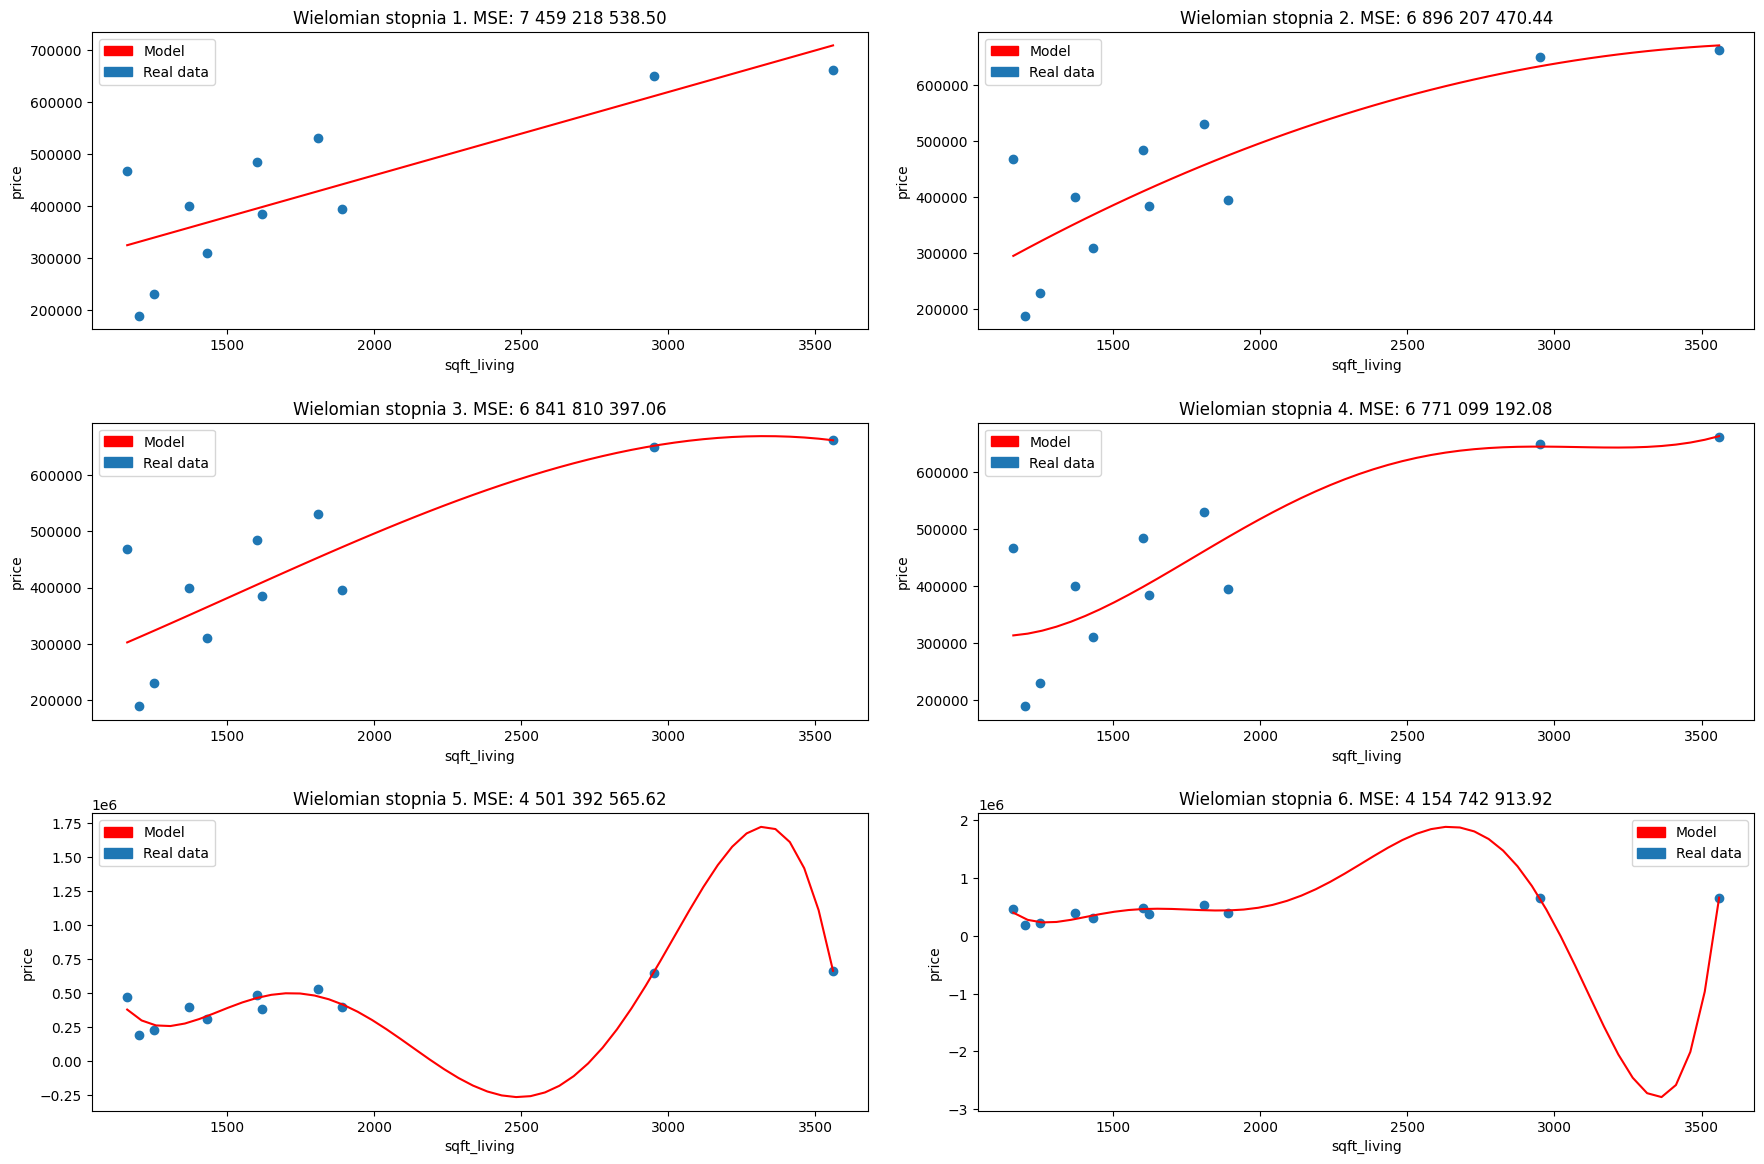

In [206]:
number=6
rows = int(np.ceil(number/2))
fig,axes = plt.subplots(nrows=rows,ncols=2, figsize=(18,12))
axes = axes.flatten()
down = 10
up = 20

for i in range(number):

    y_small = df.loc[down:up,['price']].to_numpy().reshape(-1, 1)
    x_small = df.loc[down:up,['sqft_living']].to_numpy().reshape(-1, 1)
    poly_reg=PolynomialFeatures(degree=i+1)
    x_poly_small=poly_reg.fit_transform(x_small)
    x_poly_small = x_poly_small[:,1:]
    linear_model.fit(x_poly_small, y_small)
    pred=linear_model.predict(x_poly_small)
    mean_squared_error=metrics.mean_squared_error(y_small,pred)

    x_lin = np.linspace(min(x_small), max(x_small))
    x_input = poly_reg.fit_transform(x_lin)[:,1:]
    y_lin = linear_model.predict(x_input)

    axis = axes[i]
    axis.scatter(x_small, y_small)
    axis.plot(x_lin, y_lin, color='r')
    axis.set(xlabel='sqft_living', ylabel='price')
    red_patch = mpatches.Patch(color='red', label='Model')
    blue_patch = mpatches.Patch(color='#1f77b4', label='Real data')
    axis.legend(handles=[red_patch, blue_patch])
    mse = int(mean_squared_error)
    axis.set_title(f"Wielomian stopnia {i+1}. MSE: {format(mse, ',d').replace(',',' ')}.{str(mean_squared_error-mse)[2:4]}")
fig.tight_layout(pad=2.0)

---

## Podsumowanie

Zaczęliśmy od pytania: **czy da się przewidzieć cenę mieszkania?** I okazuje się, że tak — wystarczy kilka wzorów i trochę danych.

Poznaliśmy **regresję liniową** — jeden z najprostszych i najważniejszych modeli uczenia maszynowego. Model zakłada, że między zmienną objaśniającą (np. powierzchnią mieszkania) a objaśnianą (ceną) istnieje zależność liniowa: $\hat{y} = a_1 \cdot x + a_0$. Parametry $a_0$ i $a_1$ wyznaczamy analitycznie — przez przyrównanie pochodnej **funkcji kosztu MSE** do zera. To podejście daje nam dokładny wynik bez żadnej iteracji.

Następnie rozszerzyliśmy model na **wiele zmiennych objaśniających** używając notacji macierzowej. Jeden wzór — $w = (X^T X)^{-1} X^T y$ — działa niezależnie od tego, czy mamy jedną zmienną czy sto. Zobaczyliśmy też, jak **feature engineering** (tworzenie nowych cech z istniejących, np. $x^2, x^3$) pozwala dopasować krzywą zamiast prostej — bez zmiany samego algorytmu.

Na koniec napotkaliśmy **overfitting**: model wielomianowy wysokiego stopnia idealnie "przytuliał" się do danych treningowych, ale na nowych danych dawał złe wyniki. To jedna z najważniejszych pułapek w uczeniu maszynowym — i powód, dla którego prostszy model często wygrywa z bardziej elastycznym.

Przez cały notebook pracowaliśmy też z dobrymi praktykami: **eksplorowaliśmy dane** zanim zaczęliśmy modelować, **usunęliśmy oczywisty błąd** (33 sypialnie), zamknęliśmy model w **klasę z interfejsem `fit`/`predict`** — dokładnie takim samym, jakiego używa scikit-learn.

---

## Pytania podsumowujące

Spróbuj odpowiedzieć na poniższe pytania samodzielnie, a potem rozwiń odpowiedź.

---

**Jakie były trzy grupy w ramach uczenia maszynowego?**

<details>
<summary>Odpowiedź</summary>

Uczenie z nadzorem, uczenie bez nadzoru, uczenie ze wzmocnieniem.

</details>

---

**Jaką funkcję kosztu wykorzystywaliśmy w zadaniu regresji?**

<details>
<summary>Odpowiedź</summary>

Błąd średniokwadratowy (MSE — Mean Squared Error).

</details>

---

**W jaki sposób wyznaczyliśmy analitycznie parametry regresji liniowej?**

<details>
<summary>Odpowiedź</summary>

Przez przyrównanie pochodnej funkcji kosztu do zera.

</details>

---

**Czym jest overfitting?**

<details>
<summary>Odpowiedź</summary>

Zbytnim dopasowaniem się modelu do danych — predykcja modelu jest niemiarodajna dla danych testowych.

</details>

---

**Czym jest regresja i czym różni się od klasyfikacji?**

<details>
<summary>Odpowiedź</summary>

Regresja przewiduje wartość ciągłą (np. cenę mieszkania). Klasyfikacja przypisuje obserwację do jednej z dyskretnych klas (np. spam / nie-spam).

</details>

---

**Jak uogólnić model liniowy na wiele zmiennych za pomocą macierzy?**

<details>
<summary>Odpowiedź</summary>

Zamiast skalarów $a_0, a_1$ używamy wektora wag $w$ i macierzy danych $X$ (z dodaną kolumną jedynek). Wzór na optymalny $w$ to $w = (X^T X)^{-1} X^T y$ — działa dla dowolnej liczby zmiennych.

</details>

---

**Czym jest feature engineering na przykładzie regresji wielomianowej?**

<details>
<summary>Odpowiedź</summary>

Tworzenie nowych cech z istniejących. W regresji wielomianowej tworzymy kolumny $x^2, x^3, \ldots$ z oryginalnej cechy $x$ i podajemy je jako dodatkowe zmienne. Model pozostaje liniowy względem parametrów, ale może dopasować krzywą do danych.

</details>

---

## Gdzie szukać dalej?

### Po polsku

- **[Mirosław Mamczur — blog](https://miroslawmamczur.pl/)** — blog polskiego data scientista, przystępnie pisany
- **[Pasja Informatyki](https://pasja-informatyki.pl/)** — kursy po polsku, szerszy kontekst programowania i algorytmów
- **Helion** — polskie tłumaczenie Auréliena Gérona *Uczenie maszynowe z użyciem Scikit-Learn, Keras i TensorFlow* (jeden z lepszych podręczników ML)

### Po angielsku

- **[StatQuest — Linear Regression](https://www.youtube.com/watch?v=nk2CQITm_eo)** — Josh Starmer tłumaczy bardzo wizualnie
- **[Seeing Theory — Regression](https://seeing-theory.brown.edu/regression-analysis/index.html)** — interaktywne wizualizacje z Brown University
- **[scikit-learn: Linear Models](https://scikit-learn.org/stable/modules/linear_model.html)** — dokumentacja z przykładami
